# 24장 · LCEL로 구성하는 RAG와 인용 검증

RAG 체인에서는 질문과 검색 근거가 함께 모델 입력이 됩니다. 답변이 인용한 ID를 검색 목록과 대조하면 근거 밖의 인용을 찾을 수 있습니다.

검색한 문서는 휴관일을 설명하는데 답변은 엉뚱한 쪽을 인용할 수 있습니다. 검색 결과를 프롬프트에 넣고, 모델이 쓴 출처가 그 결과 안에 실제로 있는지 확인하는 첫 RAG를 완성합니다.

실행을 확인한 커널은 Python 3.12.15입니다. 예제에 사용한 외부 패키지는 langchain-core 1.6.12입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## 검색 문서를 프롬프트 문맥으로 변환

23장의 검색 함수를 호출한 뒤에는 이미 고른 문서를 그대로 사용합니다. 질문과 근거는 각각 question과 context에 넣습니다. 아래 제공 함수는 잘못된 쪽 번호, 출처 누락, 중복 ID를 거부합니다.


### 검색 결과를 LCEL 입력으로 바꾸기

<p>검색 결과인 문서 목록에서 ID·출처·쪽·본문을 묶어 context를 만듭니다. question은 질문 칸에 그대로 넣습니다. 두 입력이 프롬프트의 서로 다른 변수로 들어가는지 확인하세요.</p>


#### 질문과 검색 문맥 조립

<pre><code>question = "휴관 요일은 언제인가요?"
hits = retrieve(question, k=1)
context = format_context(hits)</code></pre><p>셀 01의 마지막 세 줄입니다. hits에는 문서 한 건이, context에는 그 문서의 ID·출처·2쪽 본문이 들어갑니다. 셀 02가 같은 문맥을 답변에 사용합니다.</p>


### 셀 01 · format_context()로 문맥 조립

셀 맨 아래의 question 한 줄에서 질문을 고릅니다. 먼저 휴관 질문을 실행해 첫 줄의 문서 ID와 둘째 줄의 원문을 읽으세요.


In [1]:
documents = [
  {"id":"library-1","text":"도서 대출 기간은 14일입니다.","source":"가상 도서관 이용 안내","page":1},
  {"id":"library-2","text":"도서관은 월요일에 휴관합니다.","source":"가상 도서관 이용 안내","page":2},
  {"id":"library-3","text":"무인 반납함은 24시간 이용할 수 있습니다.","source":"가상 도서관 이용 안내","page":3}
]

import re

class DataContractError(ValueError):
    """저장된 근거 또는 검색 결과의 형태가 잘못되었습니다."""

def validate_request(question, k=2):
    if not isinstance(question, str) or not question.strip():
        raise ValueError("질문은 비어 있지 않은 문자열이어야 합니다.")
    if isinstance(k, bool) or not isinstance(k, int) or k < 1:
        raise ValueError("k는 양의 정수여야 합니다.")
    return question.strip()

def validate_documents(documents):
    if not isinstance(documents, list):
        raise DataContractError("검색 결과는 문서 목록이어야 합니다.")
    rows, seen = [], set()
    for item in documents:
        if not isinstance(item, dict):
            raise DataContractError("출처 객체가 필요합니다. 문자열 상태는 먼저 변환하세요.")
        if any(not isinstance(item.get(key), str) or not item[key].strip()
               for key in ("id", "text", "source")):
            raise DataContractError("id·본문·출처가 필요합니다.")
        page = item.get("page")
        if isinstance(page, bool) or not isinstance(page, int) or page < 1:
            raise DataContractError("페이지는 1 이상의 정수여야 합니다.")
        if item["id"] in seen:
            raise DataContractError("문서 ID가 중복되었습니다.")
        # 인용 문법 [id]와 충돌하는 ID는 입력 단계에서 막습니다.
        if not re.fullmatch(r"[A-Za-z0-9_.:-]+", item["id"]):
            raise DataContractError("문서 ID는 영문·숫자·_ . : -만 사용합니다.")
        seen.add(item["id"])
        rows.append({key: item[key] for key in ("id", "text", "source", "page")})
    return rows

def format_context(documents):
    return "\n\n".join(f"[{d['id']}] {d['source']} / p.{d['page']}\n{d['text']}"
                       for d in validate_documents(documents))

terms = ("대출", "휴관", "반납")

def teaching_vector(text):
    return [float(term in text) for term in terms]

def retrieve(question, k=2, page=None):
    question = validate_request(question, k)
    query = teaching_vector(question)
    if not any(query):
        return []
    pool = [d for d in documents if page is None or d["page"] == page]
    def rank(doc):
        stored = teaching_vector(doc["text"])
        return (sum((a - b) ** 2 for a, b in zip(query, stored)), doc["id"])
    return sorted(pool, key=rank)[:k]

question = "휴관 요일은 언제인가요?"
hits = retrieve(question, k=1)
context = format_context(hits)
print(context)

[library-2] 가상 도서관 이용 안내 / p.2
도서관은 월요일에 휴관합니다.


첫 줄에는 [library-2]와 자료 이름, p.2가 나옵니다. 둘째 줄은 월요일 휴관을 밝힌 원문입니다. 이 둘을 같은 문자열로 모델에 전달합니다.


### 질문과 근거가 들어가는 메시지

<p>system 메시지에는 ‘다음 근거만 읽고 사용한 ID를 표시하세요.’라는 지시와 context가 들어갑니다. human 메시지에는 question이 들어갑니다. 모델의 답을 받은 뒤에는 인용 ID도 실제 검색 목록과 대조합니다.</p>


### 셀 02 · 고정 모델과 LCEL 호출

셀 01에서 만든 질문과 검색 결과를 그대로 씁니다. 첫 문서의 본문과 ID로 이번 대본을 만든 뒤 LCEL에 전달합니다. 검색 결과가 비면 모델을 부르기 전에 멈춥니다.


In [2]:
from importlib.util import find_spec
if not hits:
    print("제공된 자료에서 확인할 수 없습니다.")
elif find_spec("langchain_core") is not None:
    from langchain_core.prompts import ChatPromptTemplate
    from langchain_core.language_models.fake_chat_models import FakeListChatModel
    from langchain_core.output_parsers import StrOutputParser
    prompt = ChatPromptTemplate.from_messages([
        ("system", "다음 근거만 읽고 사용한 ID를 표시하세요.\n{context}"), ("human", "{question}")])
    doc = hits[0]
    reply = f"{doc['text']} [{doc['id']}]"
    fixed = FakeListChatModel(responses=[reply])
    chain = prompt | fixed | StrOutputParser()
    print(chain.invoke({"question": question, "context": context}))
else:
    print("langchain-core가 설치된 수업 커널에서 실제 LCEL 연결을 실행하세요.")

도서관은 월요일에 휴관합니다. [library-2]


휴관 질문에는 월요일과 [library-2]가 나옵니다. 셀 01의 질문을 ‘대출 기간은?’으로 바꾸고 두 셀을 다시 실행하면 14일과 [library-1]이 나옵니다. ‘주차 요금은?’에는 근거가 없다는 안내가 나옵니다. 이 모델은 준비된 답 한 줄을 돌려줍니다.


### 검색 단계와 생성 단계

<p>RAG는 검색한 근거를 질문과 함께 모델 입력에 넣어 답변을 생성합니다. 검색과 생성을 나누어 관찰하면 어느 단계의 문제인지 찾기 쉽습니다.</p>

<p>search(question, k)는 23장의 네 필드 문서 목록을 반환합니다. 기본 실행은 같은 교육용 벡터를 계산하는 로컬 검색과 고정 응답 모델입니다. prompt | model | parser는 실제 LCEL 라이브러리로 연결하지만 외부 LLM에 요청하지 않습니다.</p>

<h3>첫 RAG의 실행 순서</h3>

<p>검색은 교육용 로컬 계산, 모델은 고정 응답입니다. 연결에는 실제 LCEL을 사용합니다.</p>

<table><caption>조건별 다음 단계</caption><thead><tr><th scope="col">검색 결과</th><th scope="col">이후 실행</th></tr>
</thead><tbody><tr><td>[]</td><td>no_evidence 반환 · 생성 0회 · 종료</td></tr>
<tr><td>library-2</td><td>본문과 ID를 문맥에 넣어 답변 생성</td></tr>
</tbody></table>

<article><small>STEP 01 · Retriever</small><h4>관련 문서 반환</h4>
<p>id·text·source·page를 유지합니다.</p><pre>휴관 요일은 언제인가요? → library-2</pre></article>

<article><small>STEP 02 · Python</small><h4>빈 검색 결과 판정</h4>
<p>빈 목록이면 생성하지 않습니다.</p><pre>[] → 여기서 종료
문서 있음 → 다음 단계</pre></article>

<article><small>STEP 03 · Python</small><h4>출처와 본문 포매팅</h4>
<p>질문과 근거를 별도로 넣습니다.</p><pre>context + question</pre></article>

<article><small>STEP 04 · LCEL</small><h4>답변 문자열 반환</h4>
<p>인용 id를 검색 결과와 대조합니다.</p><pre>월요일 휴관 · 출처 [library-2]</pre></article>


### 고정 모델을 이용해 연결 확인하기

<p>FakeListChatModel은 준비된 휴관 안내를 돌려줍니다. 질문·문맥·파서를 연결해 최종 문자열이 나오는지 시험할 수 있습니다. 고정 응답을 사용했으므로 다른 질문에 답하는 능력까지 평가한 결과는 아닙니다.</p>


## 검색 ID와 생성 답변의 인용 대조

제공된 answer_question은 검색과 생성을 함수로 받습니다. 예제에서는 두 함수가 한 질문의 자료와 대본만 돌려주므로 근거의 유무와 인용 검사를 따로 재현할 수 있습니다.

<!-- lesson-visual visual-citation -->
**답변에 붙은 ID는 검색 목록에 있을까요?**

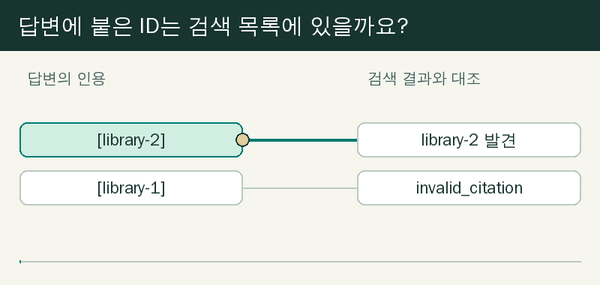

library-2만 검색한 수업 예시입니다. 답변의 인용을 검색 결과와 대조하면 같은 문장을 쓰더라도 되돌려 줄 수 있는 결과가 달라집니다.
<!-- /lesson-visual visual-citation -->


### 셀 03 · 잘못된 인용 ID 판별

여기부터는 휴관 질문과 2쪽 문서를 고정합니다. 문장은 그대로 두고 답의 인용만 1쪽으로 바꿔 검사 결과를 보세요.


In [3]:
def answer_question(question, search, generate, k=2):
    """generate(question, context) 문자열을 인용 ID 수준에서 검사합니다.

    유효한 인용 ID라도 문장 전체의 사실성이 보장되지는 않습니다.
    """
    question = validate_request(question, k)
    docs = validate_documents(search(question, k))
    if not docs:
        return {"status": "no_evidence", "answer": "제공된 자료에서 확인할 수 없습니다.",
                "sources": [], "generation_calls": 0}
    answer = generate(question, format_context(docs))
    if not isinstance(answer, str) or not answer.strip():
        raise DataContractError("생성 결과가 비어 있습니다. 거절·미완료 여부를 확인하세요.")
    cited = set(re.findall(r"\[([^\[\]]+)\]", answer))
    allowed = {d["id"] for d in docs}
    if not cited or not cited.issubset(allowed):
        return {"status": "invalid_citation", "answer": "출처 표시를 확인해야 합니다.",
                "sources": [], "generation_calls": 1}
    return {"status": "answered", "answer": answer,
            "sources": [d for d in docs if d["id"] in cited], "generation_calls": 1}

def search_closed(question, k):
    return [documents[1]]

def wrong_id(question, context):
    return "도서관은 월요일에 휴관합니다. [library-1]"

citation_question = "휴관 요일은 언제인가요?"
bad = answer_question(citation_question, search_closed, wrong_id, k=1)
print(bad["status"])

invalid_citation


invalid_citation이 나옵니다. 문장은 맞아도 library-1은 검색 결과에 없었습니다. 반대로 올바른 ID를 붙였어도 문장에 다른 요일을 쓰면 이 검사만으로는 발견하지 못합니다.


### 인용 ID 유효성 검사

<p>코드는 대괄호의 id를 모아 검색된 문서 id의 부분집합인지 검사합니다. 존재하지 않는 id나 인용이 없는 답은 invalid_citation으로 돌려 검토가 필요함을 알립니다.</p>

<p>이 검사는 인용 형식을 확인할 뿐 문장의 모든 주장이 그 문서에서 나온다는 의미 검증은 아닙니다. “대출 기간은 100일 [library-1]”은 id가 맞아 형식 검사를 통과할 수 있지만 원문과 다릅니다. 사람이 원문을 읽거나 별도의 평가가 필요합니다.</p>

<table><caption>검색 목록과 실제 인용 목록</caption><thead><tr><th scope="col">항목</th><th scope="col">대출 질문 예</th></tr>
</thead><tbody><tr><td>documents</td><td>library-1과 library-2 두 문서 객체</td></tr>
<tr><td>answer</td><td>대출 기간은 14일입니다. [library-1]</td></tr>
<tr><td>sources</td><td>library-1 문서 객체 한 개</td></tr>
<tr><td>반환 필드</td><td>status / answer / sources / generation_calls</td></tr>
</tbody></table>

<table><caption>검증 단계</caption><thead><tr><th scope="col">검사</th><th scope="col">찾을 수 있는 문제</th></tr>
</thead><tbody><tr><td>빈 근거 검사</td><td>검색 결과 없이 생성하려는 흐름</td></tr>
<tr><td>id 허용 목록</td><td>검색하지 않은 출처 번호</td></tr>
<tr><td>원문 대조</td><td>맞는 id에 잘못 연결된 주장</td></tr>
<tr><td>질문 세트 평가</td><td>반복적으로 나타나는 실패 유형</td></tr>
</tbody></table>

<p>sources는 문자열 ID 목록이 아니라 실제 인용된 id·text·source·page 객체 목록입니다. 검색한 두 번째 문서를 답변에서 사용하지 않았다면 sources에 넣지 않습니다. 팀 자료의 team-01:p-01 같은 콜론 ID도 그대로 인용할 수 있습니다.</p>

<p>[library-1]과 [unknown]을 함께 쓴 답변은 일부만 맞더라도 invalid_citation입니다. 인용을 하나도 쓰지 않은 답변도 같은 상태입니다. invalid_citation은 검토 안내와 빈 sources를 반환하며, 잘못된 답변을 성공 답변으로 내보내지 않습니다.</p>


### 과제 04 · 유효 인용과 검색 목록 대조

위의 검색 함수는 그대로 두고 올바른 문장과 ID를 반환하는 생성 함수를 전달하세요. sources에 든 문서의 쪽을 출력하세요.


In [4]:
# 새 생성 함수를 만들고 answer_question을 호출하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>def cite_closed(question, context):
    return &quot;도서관은 월요일에 휴관합니다. [library-2]&quot;

answer = answer_question(citation_question, search_closed, cite_closed, k=1)
print(answer[&quot;status&quot;], answer[&quot;sources&quot;][0][&quot;page&quot;])</code></pre>
<p>실행 결과</p><pre><code>answered 2</code></pre>
<p>answered와 2가 나옵니다. 사용자에게 전달할 sources에는 실제 인용한 문서 객체만 들어 있습니다.</p>
</details>


### 기대 근거와 실제 인용 구분하기

<p>휴관일 질문의 기준 근거는 library-2입니다. 검색 결과에 이 ID가 있는지, 답변이 실제로 이 ID를 인용했는지 따로 확인하세요. 마지막으로 ‘월요일’이라는 문장이 원문의 내용과 맞는지 읽습니다.</p>


## 빈 검색 결과의 생성 생략

주차 요금 정보가 없는 질문에 답을 써 달라고 부르면 그럴듯한 요금이 만들어질 수 있습니다. 빈 검색 결과는 생성기 앞에서 정상적으로 처리하고, 통신 실패는 오류로 남깁니다.


### 검색 결과가 비었을 때 생성 호출 수 추적

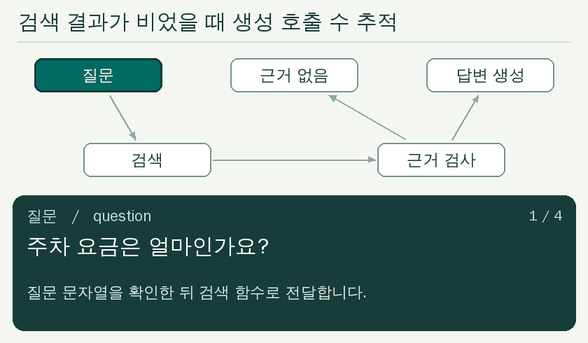

주차 요금 질문에 no_hits가 빈 목록을 돌려줍니다. 생성기로 넘긴 함수가 무엇이든 이 실행에서는 한 번도 불리지 않습니다.


### 과제 05 · 근거 부재와 생성 호출 수

항상 빈 목록을 돌려주는 검색 함수를 건네고 상태와 generation_calls를 출력하세요.


In [5]:
# 빈 결과를 돌려주는 검색 함수를 작성하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>def no_hits(question, k):
    return []

unanswered = answer_question(&quot;주차 요금은 얼마인가요?&quot;, no_hits, wrong_id)
print(unanswered[&quot;status&quot;], unanswered[&quot;generation_calls&quot;])</code></pre>
<p>실행 결과</p><pre><code>no_evidence 0</code></pre>
<p>no_evidence 0입니다. 생성기 자리에 잘못된 ID를 쓰는 함수가 있었어도 이번에는 호출하지 않았습니다. 시간 초과로 검색에 실패한 경우라면 ‘자료에 없음’과 구분해 알려야 합니다.</p>
</details>


### 빈 문서 목록에서 생성 생략

<p>answer_question은 문서 검증 직후 docs가 비었는지 확인합니다. 빈 목록이면 no_evidence와 빈 sources를 바로 반환해 generation_calls가 0이 됩니다. 검색 함수가 예외를 낸 상황과는 다른 경로입니다.</p>


## 돌아보기

본문 ‘월요일’을 ‘화요일’로만 바꾼 고정 답변을 넣으면 ID 검사가 무엇을 놓칠까요? 원문과 답 문장을 사람이 대조해야 하는 이유를 이 한 건으로 설명할 수 있습니다.

### 첫 RAG의 실행 순서

**질문 관련 문서 받기**　id·text·source·page를 유지합니다.

```
휴관 요일은 언제인가요? → library-2
```

**빈 근거인지 확인**　빈 목록이면 생성하지 않습니다.

```
[] → 여기서 종료
문서 있음 → 다음 단계
```

**출처와 본문 묶기**　질문과 근거를 별도로 넣습니다.

```
context + question
```

**답변 문자열 받기**　인용 id를 검색 결과와 대조합니다.

```
월요일 휴관 · 출처 [library-2]
```
